# Clasificación: SVC

**`probability=True`:** el SVC no produce probabilidades de forma nativa. Con `probability=True`, scikit-learn ajusta una **calibración de Platt interna** (un CV interno de 5 folds), lo que hace el entrenamiento bastante **más lento**, sobre todo con SMOTENC, que casi duplica las filas. Sus probabilidades quedan en la escala de la prevalencia real, así que el umbral 0.5 puede marcar pocos positivos; eso se corrige en la fase 3. `probability=True` está marcado como obsoleto desde scikit-learn 1.9, pero funciona en la versión fijada (1.9.1).

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from Modelado import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_CLF, ESTRATEGIAS, N_ITER_FASE1,
    cargar_split, separar_x_y, crear_cv, dispositivo_modelo, verificar_smotenc,
    describir_espacio, ejecutar_fase1, formatear_tabla_cv, graficar_estrategias, elegir_mejor, guardar_fase1,
    formatear_hiperparametros, tabla_hiperparametros,
)

CLAVE = "svc"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_modelo(CLAVE),
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,SVC (RBF)
USAR_GPU,True
GPU detectada por librería,"xgboost: cuda, catboost: GPU, lightgbm: cuda"
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y(df_train)
cv = crear_cv(SEED)

pd.DataFrame({
    "Filas": [len(X_train)],
    "Predictores": [X_train.shape[1]],
    "Deprimidos": [int(y_train.sum())],
    "Prevalencia": [round(y_train.mean(), 3)],
}, index=pd.Index(["Train"], name="Conjunto"))

,Filas,Predictores,Deprimidos,Prevalencia
Conjunto,,,,
Train,3848,6,630,0.164


### Estrategias de Manejo del Desbalance

Se comparan las tres estrategias de [manejo del desbalance](#mod-desbalance). En el SVC, los pesos de clase se aplican con `class_weight="balanced"`.

In [4]:
tabla_clases, tabla_sexo = verificar_smotenc(X_train, y_train, seed=SEED)
display(tabla_clases)
display(tabla_sexo)

✓ sex solo toma los valores ['Boy', 'Girl']
✓ Clases balanceadas: {0: 3218, 1: 3218}


,Antes,Después,Sintéticos
Deprimido,,,
0,3218,3218,0
1,630,3218,2588


Deprimido,0,1
Sexo,,
Boy,1789,770
Girl,1429,2448


### Espacio de Búsqueda

Se exploraron 20 combinaciones aleatorias por estrategia. Se variaron la penalización `C` en escala logarítmica (0.01 a 100) y el ancho del kernel RBF, `gamma`, que se fija en `"scale"` o se toma log-uniforme entre 0.001 y 1 (aproximadamente la mitad de las combinaciones usa `"scale"`).

In [5]:
describir_espacio(CLAVE).style.set_caption(f"Combinaciones por estrategia: {N_ITER_FASE1[CLAVE]}")

,Valores
Hiperparámetro,
C,log-uniforme entre 0.01 y 100
gamma,scale o log-uniforme entre 0.001 y 1


### Validación Cruzada por Estrategia

In [6]:
tabla, pipelines, hiperparametros = ejecutar_fase1(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo (sin balanceo)  PR-AUC = 0.3471 ± 0.0455  (19 s)
✓ Pesos de clase         PR-AUC = 0.3927 ± 0.0476  (21 s)
✓ SMOTENC                PR-AUC = 0.3906 ± 0.0439  (56 s)


In [7]:
vista = formatear_tabla_cv(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(0)
vista.rename(index=ESTRATEGIAS)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Tiempo (s)
Estrategia,,,,,,,
Nativo (sin balanceo),0.347 ± 0.045,0.619 ± 0.025,0.608 ± 0.081,0.084 ± 0.019,0.147 ± 0.028,0.841 ± 0.003,19.0
Pesos de clase,0.393 ± 0.048,0.754 ± 0.034,0.560 ± 0.052,0.137 ± 0.029,0.217 ± 0.039,0.840 ± 0.004,21.0
SMOTENC,0.391 ± 0.044,0.755 ± 0.031,0.307 ± 0.026,0.660 ± 0.058,0.419 ± 0.036,0.700 ± 0.019,56.0


Aquí la estrategia sí cambia la capacidad discriminativa. Con pesos de clase y con SMOTENC, el SVC obtiene una PR-AUC de 0.393 ± 0.048 y 0.391 ± 0.044, y una ROC-AUC de 0.754 ± 0.034 y 0.755 ± 0.031, prácticamente iguales. El nativo, en cambio, cae a una PR-AUC de 0.347 ± 0.045 y, sobre todo, a una ROC-AUC de 0.619 ± 0.025, unas cuatro desviaciones por debajo. Sin balanceo, la frontera del SVC queda dominada por la clase mayoritaria y su función de decisión ordena peor a los positivos.

Con el umbral de 0.5, el nativo y el de pesos de clase se comportan casi igual: precision de 0.608 ± 0.081 y 0.560 ± 0.052, recall de apenas 0.084 ± 0.019 y 0.137 ± 0.029, y F1 de 0.147 ± 0.028 y 0.217 ± 0.039. Su accuracy (0.841 ± 0.003 y 0.840 ± 0.004) apenas supera la de predecir siempre “no deprimido” (1 − 0.164 = 0.836), así que no refleja capacidad predictiva. Los pesos de clase no desplazan el punto de operación porque la calibración de Platt interna (`probability=True`) devuelve probabilidades en la escala de la prevalencia real, así que pocas superan 0.5.

Solo SMOTENC, que balancea también los datos con los que se calibran las probabilidades, sube el recall a 0.660 ± 0.058, con una precision de 0.307 ± 0.026, un F1 de 0.419 ± 0.036 y una accuracy de 0.700 ± 0.019. A cambio, es la estrategia más lenta (54 s frente a unos 20 s), porque casi duplica las filas de entrenamiento.

In [8]:
# Mejores hiperparámetros por estrategia
tabla_hiperparametros(hiperparametros)

,C,gamma
Estrategia,,
Nativo (sin balanceo),2.4400,scale
Pesos de clase,2.7960,0.00105
SMOTENC,0.1474,0.01256


Cada estrategia eligió una configuración distinta. El nativo usa `gamma="scale"` (del orden de 0.2 con estas 6 variables) y `C` ≈ 2.4. Los pesos de clase usan un `gamma` muy pequeño (≈ 0.001) con `C` ≈ 2.8, lo que produce una frontera muy suave, casi lineal, y SMOTENC una penalización más débil (`C` ≈ 0.15) con `gamma` ≈ 0.013, también una frontera suave. Que las dos estrategias con mejor PR-AUC prefieran fronteras suaves es coherente con una señal simple, cercana a lineal.

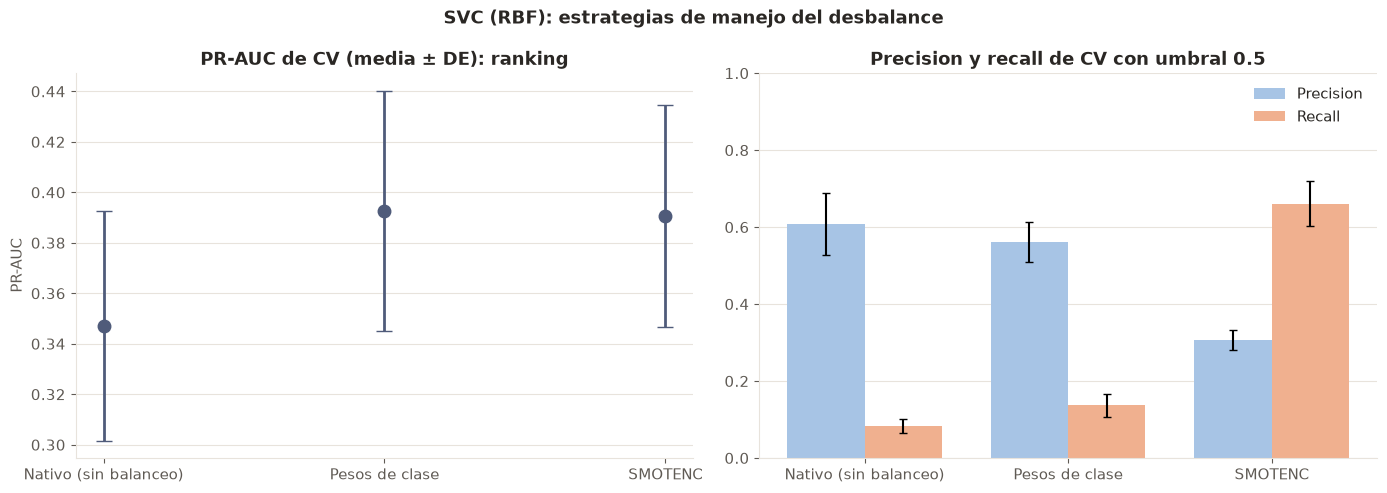

In [9]:
fig = graficar_estrategias(tabla, NOMBRES_CLF[CLAVE])
plt.show()

La gráfica muestra las dos diferencias del SVC. En la PR-AUC, el nativo queda por debajo (~0.35 frente a ~0.39), aunque sus barras de desviación todavía tocan las de las otras estrategias. En el punto de operación con umbral 0.5, el nativo y los pesos de clase casi no predicen la clase minoritaria (recall ~0.08 y ~0.14, precision ~0.61 y ~0.56), mientras que SMOTENC desplaza el punto de operación hacia más recall (~0.66) a costa de menos precision (~0.31).

### Selección del Mejor Modelo SVC

In [10]:
estrategia_ganadora, explicacion = elegir_mejor(tabla)

pd.Series({
    "Estrategia ganadora": ESTRATEGIAS[estrategia_ganadora],
    "PR-AUC de CV": f"{tabla.loc[estrategia_ganadora, 'PR-AUC media']:.4f} ± {tabla.loc[estrategia_ganadora, 'PR-AUC DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[estrategia_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,SVC (RBF)
Estrategia ganadora,Pesos de clase
PR-AUC de CV,0.3927 ± 0.0476
Hiperparámetros,"C=2.796, gamma=0.00105"
Criterio,Se elige 'pesos': tiene la mayor PR-AUC media de CV (0.3927 ± 0.0476).


Se eligen los pesos de clase, que tienen la PR-AUC media más alta (0.3927 ± 0.0476) y una ROC-AUC de 0.754. SMOTENC queda prácticamente empatado (0.0021 menos), pero tarda más del doble en entrenar; el nativo queda claramente por debajo, sobre todo en ROC-AUC (0.619). Su recall de 0.137 con umbral 0.5.

### Guardado

In [11]:
ganador = guardar_fase1(
    CLAVE, tabla, estrategia_ganadora, pipelines[estrategia_ganadora],
    hiperparametros[estrategia_ganadora], explicacion,
)